# Customer Telecommunications Churn Prediction

**Assignment:** Machine Learning Process - Classification

This notebook documents and executes the complete machine learning workflow for predicting customer churn.

## 1. Problem Definition

**Business problem:** Identify telecommunications customers who are likely to cancel their service.

**Goal:** Build a binary classifier that estimates whether `Churn` is `Yes` or `No`.

**Success criteria:** Optimize ROC-AUC and prioritize recall so that most at-risk customers can receive a retention offer. Accuracy, precision, F1-score, and the confusion matrix are also reported.

## 2. Data Collection

In [ ]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")

DATA_PATH = Path("data/Telco-Customer-Churn.csv.xlsx")
OUTPUT_DIR = Path("artifacts")
OUTPUT_DIR.mkdir(exist_ok=True)
print(f"Dataset path: {DATA_PATH.resolve()}")

Dataset path: /home/derara/projects/machine-learing-project/customer-telecommunications-churn-prediction/data/Telco-Customer-Churn.csv.xlsx


The source file is an Excel container whose first column contains comma-separated records. The following cells normalize it into a standard DataFrame.

In [ ]:
raw = pd.read_excel(DATA_PATH)
column_line = str(raw.columns.to_list()[0])
columns = [name.strip() for name in column_line.split(",")]
row_values = raw.to_numpy(dtype=str).reshape(-1)
rows = (
    pd.Series(row_values, dtype="string")
    .dropna()
    .astype(str)
    .str.split(",", expand=True)
)
rows.columns = columns

for column in ("SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"):
    rows[column] = pd.to_numeric(rows[column], errors="coerce")

rows["Churn"] = rows["Churn"].str.strip()
df = rows.drop(columns=["customerID"]).drop_duplicates()
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (7021, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Data Exploration and Preparation

### 3.1 Dataset overview

In [3]:
df.info()
print("\nMissing values:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nTarget distribution:")
print(df["Churn"].value_counts())

<class 'pandas.DataFrame'>
Index: 7021 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7021 non-null   str    
 1   SeniorCitizen     7021 non-null   int64  
 2   Partner           7021 non-null   str    
 3   Dependents        7021 non-null   str    
 4   tenure            7021 non-null   int64  
 5   PhoneService      7021 non-null   str    
 6   MultipleLines     7021 non-null   str    
 7   InternetService   7021 non-null   str    
 8   OnlineSecurity    7021 non-null   str    
 9   OnlineBackup      7021 non-null   str    
 10  DeviceProtection  7021 non-null   str    
 11  TechSupport       7021 non-null   str    
 12  StreamingTV       7021 non-null   str    
 13  StreamingMovies   7021 non-null   str    
 14  Contract          7021 non-null   str    
 15  PaperlessBilling  7021 non-null   str    
 16  PaymentMethod     7021 non-null   str    
 17  MonthlyChar

### 3.2 Duplicate and inconsistent value checks

In [4]:
print("Duplicate rows:", df.duplicated().sum())
for column in df.select_dtypes(include="object").columns:
    print(f"{column}: {sorted(df[column].dropna().unique())}")

Duplicate rows: 0
gender: ['Female', 'Male']
Partner: ['No', 'Yes']
Dependents: ['No', 'Yes']
PhoneService: ['No', 'Yes']
MultipleLines: ['No', 'No phone service', 'Yes']
InternetService: ['DSL', 'Fiber optic', 'No']
OnlineSecurity: ['No', 'No internet service', 'Yes']
OnlineBackup: ['No', 'No internet service', 'Yes']
DeviceProtection: ['No', 'No internet service', 'Yes']
TechSupport: ['No', 'No internet service', 'Yes']
StreamingTV: ['No', 'No internet service', 'Yes']
StreamingMovies: ['No', 'No internet service', 'Yes']
Contract: ['Month-to-month', 'One year', 'Two year']
PaperlessBilling: ['No', 'Yes']
PaymentMethod: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn: ['No', 'Yes']


/tmp/ipykernel_11931/3616864575.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include="object").columns:


### 3.3 Exploratory visualizations

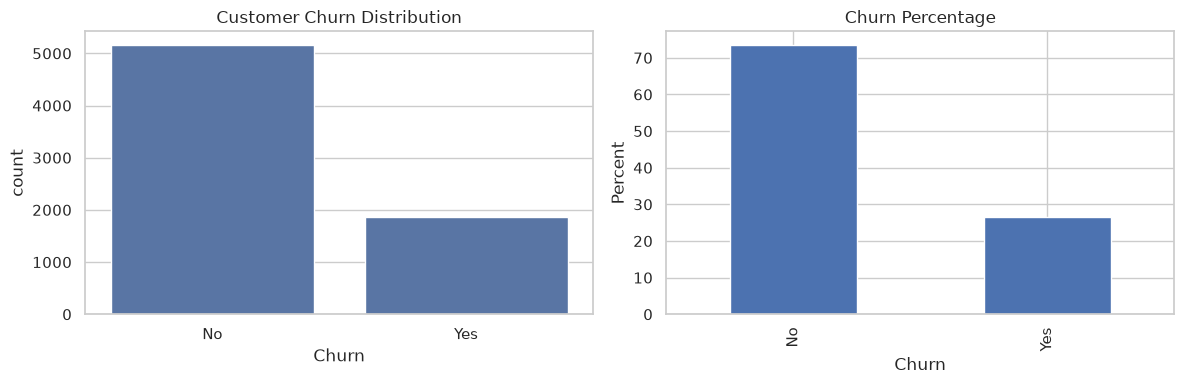

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Churn", ax=axes[0])
axes[0].set_title("Customer Churn Distribution")
(df["Churn"].value_counts(normalize=True).mul(100)).plot(kind="bar", ax=axes[1])
axes[1].set_title("Churn Percentage")
axes[1].set_ylabel("Percent")
plt.tight_layout()
plt.show()

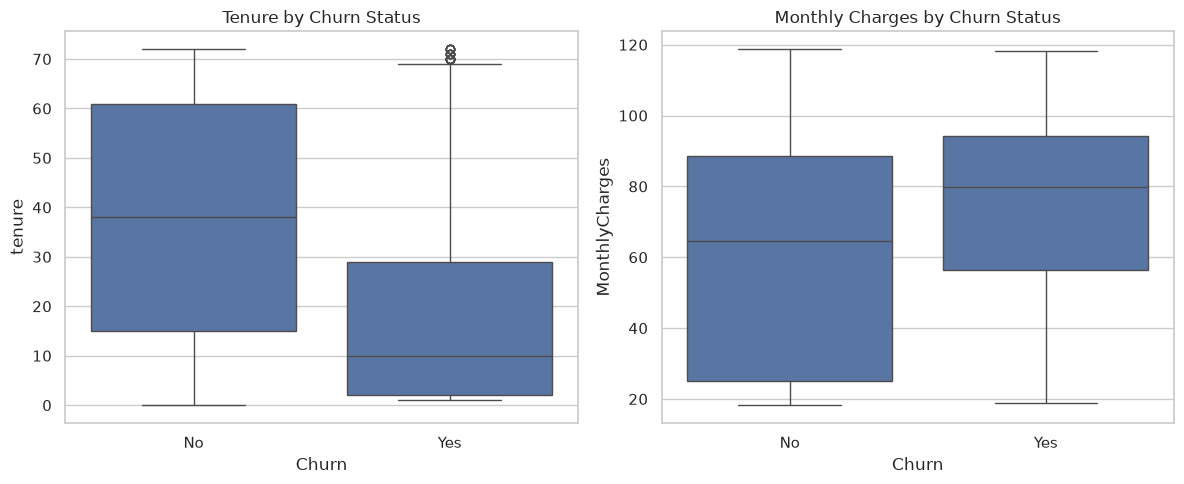

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[0])
axes[0].set_title("Tenure by Churn Status")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Monthly Charges by Churn Status")
plt.tight_layout()
plt.show()

### 3.4 Feature engineering and target encoding

In [7]:
df["Target"] = (df["Churn"].str.lower() == "yes").astype(int)
X = df.drop(columns=["Churn", "Target"])
y = df["Target"]

numeric_columns = X.select_dtypes(include="number").columns.tolist()
categorical_columns = X.select_dtypes(exclude="number").columns.tolist()

print("Numeric features:", numeric_columns)
print("Categorical features:", categorical_columns)
print("Class balance:", y.value_counts(normalize=True).round(3).to_dict())

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Class balance: {0: 0.736, 1: 0.264}


### 3.5 Train-test split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

Training shape: (5616, 19)
Test shape: (1405, 19)


Numeric values are median-imputed and standardized. Categorical values are mode-imputed and one-hot encoded. Unknown categories at prediction time are safely ignored.

In [ ]:
numeric_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ]
)

## 4. Algorithm Selection

We compare a transparent Logistic Regression baseline with a nonlinear Random Forest. Both are suitable for this supervised binary-classification task.

## 5. Model Development and Training

### 5.1 Logistic Regression

In [ ]:
logistic_pipeline = Pipeline(
    [
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
        ),
    ]
)

logistic_grid = {"model__C": [0.1, 1.0, 10.0]}
logistic_search = GridSearchCV(
    logistic_pipeline, logistic_grid, scoring="roc_auc", cv=5, n_jobs=-1
)
logistic_search.fit(X_train, y_train)
print("Best parameters:", logistic_search.best_params_)
print("Best cross-validation ROC-AUC:", round(logistic_search.best_score_, 4))

Best parameters: {'model__C': 10.0}
Best cross-validation ROC-AUC: 0.8465


### 5.2 Random Forest

In [ ]:
forest_pipeline = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(random_state=42, class_weight="balanced")),
    ]
)

forest_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [8, 16, None],
    "model__min_samples_leaf": [1, 2],
}
forest_search = GridSearchCV(
    forest_pipeline, forest_grid, scoring="roc_auc", cv=5, n_jobs=-1
)
forest_search.fit(X_train, y_train)
print("Best parameters:", forest_search.best_params_)
print("Best cross-validation ROC-AUC:", round(forest_search.best_score_, 4))

Best parameters: {'model__max_depth': 8, 'model__min_samples_leaf': 2, 'model__n_estimators': 400}
Best cross-validation ROC-AUC: 0.8467


## 6. Model Evaluation and Hyperparameter Tuning

In [12]:
searches = {
    "Logistic Regression": logistic_search,
    "Random Forest": forest_search,
}

results = {}
for name, search in searches.items():
    predictions = search.predict(X_test)
    probabilities = search.predict_proba(X_test)[:, 1]
    results[name] = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    }

results_df = pd.DataFrame(results).T
print(results_df.round(4).to_string())

                     Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression    0.7395     0.5052  0.7823    0.6139   0.8397
Random Forest          0.7530     0.5224  0.7823    0.6265   0.8407


Selected model: Random Forest

Classification report:


              precision    recall  f1-score   support

    No churn       0.90      0.74      0.82      1033
       Churn       0.52      0.78      0.63       372

    accuracy                           0.75      1405
   macro avg       0.71      0.76      0.72      1405
weighted avg       0.80      0.75      0.77      1405



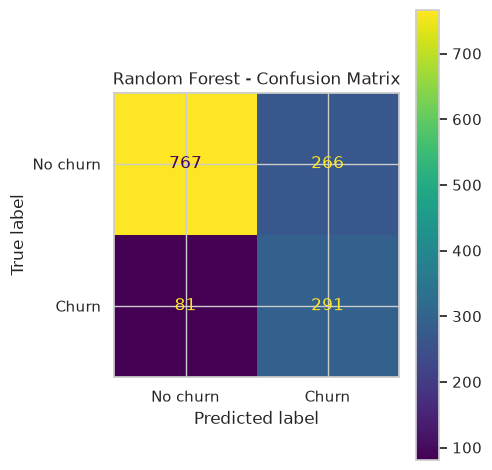

In [13]:
best_name = str(results_df["ROC-AUC"].idxmax())
best_search = searches[best_name]
print("Selected model:", best_name)

predictions = best_search.predict(X_test)
print("\nClassification report:")
print(classification_report(y_test, predictions, target_names=["No churn", "Churn"]))

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, display_labels=["No churn", "Churn"], ax=ax
)
ax.set_title(f"{best_name} - Confusion Matrix")
plt.tight_layout()
plt.show()

## 7. Final Model Testing and Saving

In [ ]:
joblib.dump(best_search.best_estimator_, OUTPUT_DIR / "churn_model.joblib")
joblib.dump(
    {
        "numeric_columns": numeric_columns,
        "categorical_columns": categorical_columns,
    },
    OUTPUT_DIR / "feature_metadata.joblib",
)

print("Saved:", (OUTPUT_DIR / "churn_model.joblib").resolve())

Saved: /home/derara/projects/machine-learing-project/customer-telecommunications-churn-prediction/artifacts/churn_model.joblib


## 8. Model Deployment

The trained pipeline is saved and used by `app.py`, a Streamlit web application. Launch it with:

```bash
uv run streamlit run app.py
```

The application accepts customer attributes, computes `predict_proba`, and reports the churn probability.

## 9. Monitoring and Maintenance

- Monitor accuracy, precision, recall, F1-score, and ROC-AUC over time.
- Track prediction volume and response latency.
- Monitor feature and target distributions for drift.
- Retrain periodically or when sustained performance degradation is observed.
- Record model version, data version, deployment date, and replacement criteria.

## 10. Conclusion

In [15]:
summary = results_df.loc[str(best_name)].round(4)
print(f"The selected {best_name} model achieved:")
for metric, value in summary.items():
    print(f"- {metric}: {value:.4f}")

The selected Random Forest model achieved:
- Accuracy: 0.7530
- Precision: 0.5224
- Recall: 0.7823
- F1-score: 0.6265
- ROC-AUC: 0.8407
